In [1]:

# Human Activity Recognition Using LSTM
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

import os
import zipfile

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping


In [11]:

import zipfile
import os

# First ZIP file
outer_zip = "/content/human+activity+recognition+using+smartphones.zip"

# Extract the inner ZIP
with zipfile.ZipFile(outer_zip, "r") as z:
    z.extract("UCI HAR Dataset.zip", "/content/")

print("Inner ZIP extracted successfully!")

Inner ZIP extracted successfully!


In [14]:

inner_zip = "/content/UCI HAR Dataset.zip"

with zipfile.ZipFile(inner_zip, "r") as z:
    z.extractall("/content/")

print("dataset extracted successfully!")

dataset extracted successfully!


In [15]:

dataset_path = "/content/UCI HAR Dataset"

print(os.listdir(dataset_path))

['activity_labels.txt', 'train', 'test', 'features_info.txt', '.DS_Store', 'features.txt', 'README.txt']


In [16]:
print("Training folders:")
print(os.listdir(dataset_path + "/train"))

print("\nTesting folders:")
print(os.listdir(dataset_path + "/test"))

Training folders:
['subject_train.txt', 'y_train.txt', 'X_train.txt', 'Inertial Signals']

Testing folders:
['X_test.txt', 'y_test.txt', 'subject_test.txt', 'Inertial Signals']


LOADING THE TRAIN AND TESTING DATA

In [18]:
# Training data
X_train = pd.read_csv(
    dataset_path + "/train/X_train.txt",
    sep=r"\s+",
    header=None
)

y_train = pd.read_csv(
    dataset_path + "/train/y_train.txt",
    header=None
)

# Testing data
X_test = pd.read_csv(
    dataset_path + "/test/X_test.txt",
    sep=r"\s+",
    header=None
)

y_test = pd.read_csv(
    dataset_path + "/test/y_test.txt",
    header=None
)

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: (7352, 561)
y_train: (7352, 1)
X_test: (2947, 561)
y_test: (2947, 1)


In [19]:
signals = [
    "body_acc_x",
    "body_acc_y",
    "body_acc_z",
    "body_gyro_x",
    "body_gyro_y",
    "body_gyro_z",
    "total_acc_x",
    "total_acc_y",
    "total_acc_z"
]

# Function to load sensor data

def load_sensor_data(split):

    folder = dataset_path + "/" + split + "/Inertial Signals"

    data = []

    for signal in signals:

        file_path = folder + "/" + signal + "_" + split + ".txt"

        sensor = np.loadtxt(file_path)

        data.append(sensor)

    return np.stack(data, axis=-1)


# Load training and testing sensor data

X_train_sensor = load_sensor_data("train")

X_test_sensor = load_sensor_data("test")

print("Training sensor shape:", X_train_sensor.shape)

print("Testing sensor shape:", X_test_sensor.shape)

Training sensor shape: (7352, 128, 9)
Testing sensor shape: (2947, 128, 9)


In [20]:

activity_labels = pd.read_csv(
    dataset_path + "/activity_labels.txt",
    sep=r"\s+",
    header=None,
    names=["ID", "Activity"]
)

print(activity_labels)

   ID            Activity
0   1             WALKING
1   2    WALKING_UPSTAIRS
2   3  WALKING_DOWNSTAIRS
3   4             SITTING
4   5            STANDING
5   6              LAYING


In [21]:

print("Activity distribution in training data:")

print(
    y_train[0].value_counts().sort_index()
)

Activity distribution in training data:
0
1    1226
2    1073
3     986
4    1286
5    1374
6    1407
Name: count, dtype: int64


In [22]:

activity_counts = y_train[0].value_counts().sort_index()

for i, count in activity_counts.items():

    activity_name = activity_labels.loc[
        activity_labels["ID"] == i,
        "Activity"
    ].values[0]

    print(activity_name, ":", count)

WALKING : 1226
WALKING_UPSTAIRS : 1073
WALKING_DOWNSTAIRS : 986
SITTING : 1286
STANDING : 1374
LAYING : 1407


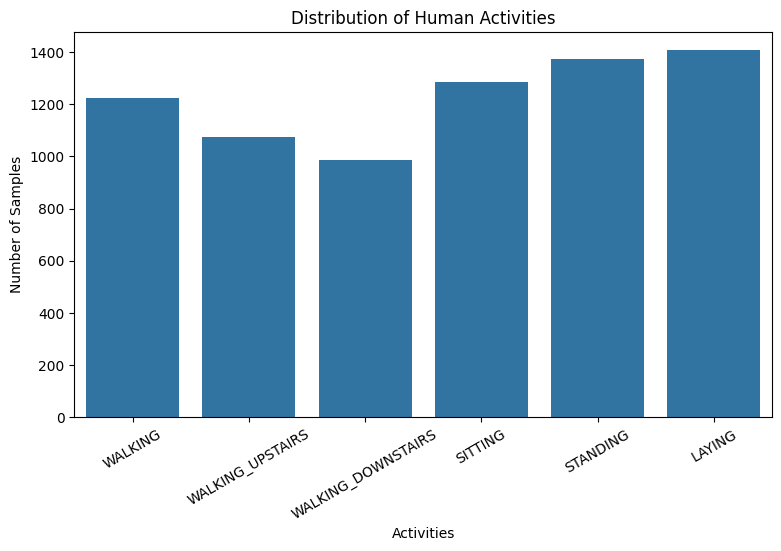

In [23]:

plt.figure(figsize=(9, 5))

sns.countplot(
    x=y_train[0],
    order=[1, 2, 3, 4, 5, 6]
)

plt.xticks(
    ticks=range(6),
    labels=activity_labels["Activity"],
    rotation=30
)

plt.title("Distribution of Human Activities")
plt.xlabel("Activities")
plt.ylabel("Number of Samples")

plt.show()

In [24]:

# Convert labels into NumPy arrays

y_train = y_train.values.flatten()
y_test = y_test.values.flatten()

# Convert labels from 1-6 to 0-5

y_train = y_train - 1
y_test = y_test - 1

print("Training labels:", np.unique(y_train))
print("Testing labels:", np.unique(y_test))

Training labels: [0 1 2 3 4 5]
Testing labels: [0 1 2 3 4 5]


In [25]:
from sklearn.model_selection import GroupShuffleSplit

# Load subject IDs
subjects_train = np.loadtxt(
    dataset_path + "/train/subject_train.txt"
).astype(int)

print("Subject IDs:", np.unique(subjects_train))
print("Total subjects:", len(np.unique(subjects_train)))

Subject IDs: [ 1  3  5  6  7  8 11 14 15 16 17 19 21 22 23 25 26 27 28 29 30]
Total subjects: 21


In [26]:
#Split training data into training and validation

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, val_idx = next(
    splitter.split(
        X_train_sensor,
        y_train,
        groups=subjects_train
    )
)

# Training data
X_tr = X_train_sensor[train_idx]
y_tr = y_train[train_idx]

# Validation data
X_val = X_train_sensor[val_idx]
y_val = y_train[val_idx]

print("Training shape:", X_tr.shape)
print("Validation shape:", X_val.shape)

Training shape: (5551, 128, 9)
Validation shape: (1801, 128, 9)


In [27]:
#APPLY NORMALISATION

scaler = StandardScaler()

# Fit only on training data
scaler.fit(
    X_tr.reshape(-1, 9)
)

# Function to normalize sensor data
def normalize_data(X):

    original_shape = X.shape

    X = X.reshape(-1, 9)

    X = scaler.transform(X)

    return X.reshape(original_shape)


# Normalize all datasets
X_tr = normalize_data(X_tr)

X_val = normalize_data(X_val)

X_test_sensor = normalize_data(X_test_sensor)


print("Training:", X_tr.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test_sensor.shape)

Training: (5551, 128, 9)
Validation: (1801, 128, 9)
Testing: (2947, 128, 9)


In [28]:

print("Mean of normalized training data:",
      np.mean(X_tr))

print("Standard deviation of normalized training data:",
      np.std(X_tr))

Mean of normalized training data: 6.690272081137556e-15
Standard deviation of normalized training data: 0.999999999999995


Create the LSTM model

In [29]:

model = Sequential([

    # Input layer
    tf.keras.Input(shape=(128, 9)),

    # LSTM layer
    LSTM(64),

    # Dropout layer
    Dropout(0.3),

    # Hidden dense layer
    Dense(32, activation="relu"),

    # Output layer
    Dense(6, activation="softmax")

])

print("LSTM model created successfully!")

LSTM model created successfully!


In [30]:

model.compile(

    optimizer="adam",

    loss="sparse_categorical_crossentropy",

    metrics=["accuracy"]

)

print("Model compiled successfully!")

Model compiled successfully!


In [31]:

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 64)             │        18,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           198 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 21,222 (82.90 KB)

 Trainable params: 21,222 (82.90 KB)

 Non-trainable params: 0 (0.00 B)

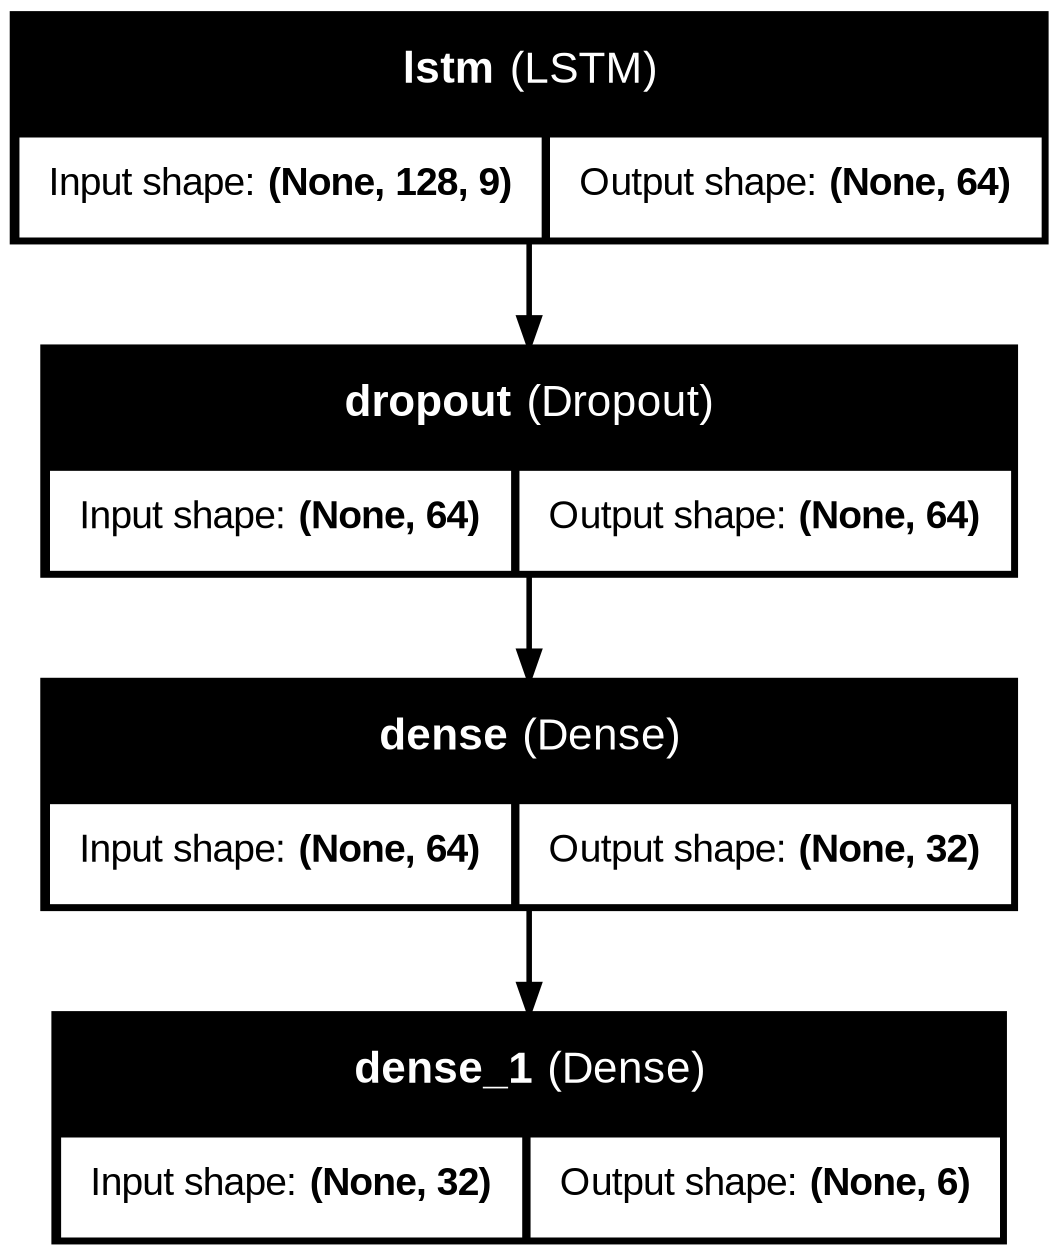

In [32]:

tf.keras.utils.plot_model(
    model,
    show_shapes=True,
    show_layer_names=True,
    to_file="LSTM_Architecture.png"
)

In [44]:
#TRAINING THE DATA

early_stop = EarlyStopping(

    monitor="val_loss",

    patience=5,

    restore_best_weights=True

)

print("Early stopping configured!")

Early stopping configured!


In [45]:

history = model.fit(

    X_tr,
    y_tr,

    validation_data=(X_val, y_val),

    epochs=40,

    batch_size=64,

    callbacks=[early_stop]

)

Epoch 1/40
87/87 ━━━━━━━━━━━━━━━━━━━━ 9s 80ms/step - accuracy: 0.5896 - loss: 1.0599 - val_accuracy: 0.8057 - val_loss: 0.5190
Epoch 2/40
87/87 ━━━━━━━━━━━━━━━━━━━━ 10s 78ms/step - accuracy: 0.8051 - loss: 0.5113 - val_accuracy: 0.9056 - val_loss: 0.3102
Epoch 3/40
87/87 ━━━━━━━━━━━━━━━━━━━━ 6s 72ms/step - accuracy: 0.8921 - loss: 0.2869 - val_accuracy: 0.9206 - val_loss: 0.3107
Epoch 4/40
87/87 ━━━━━━━━━━━━━━━━━━━━ 7s 79ms/step - accuracy: 0.8667 - loss: 0.3629 - val_accuracy: 0.9467 - val_loss: 0.1981
Epoch 5/40
87/87 ━━━━━━━━━━━━━━━━━━━━ 6s 64ms/step - accuracy: 0.9161 - loss: 0.2137 - val_accuracy: 0.9689 - val_loss: 0.1235
Epoch 6/40
87/87 ━━━━━━━━━━━━━━━━━━━━ 6s 70ms/step - accuracy: 0.9207 - loss: 0.1923 - val_accuracy: 0.9600 - val_loss: 0.1148
Epoch 7/40
87/87 ━━━━━━━━━━━━━━━━━━━━ 7s 80ms/step - accuracy: 0.9335 - loss: 0.1612 - val_accuracy: 0.9528 - val_loss: 0.1652
Epoch 8/40
87/87 ━━━━━━━━━━━━━━━━━━━━ 6s 69ms/step - accuracy: 0.9369 - loss: 0.1453 - val_accuracy: 0.9517 - 

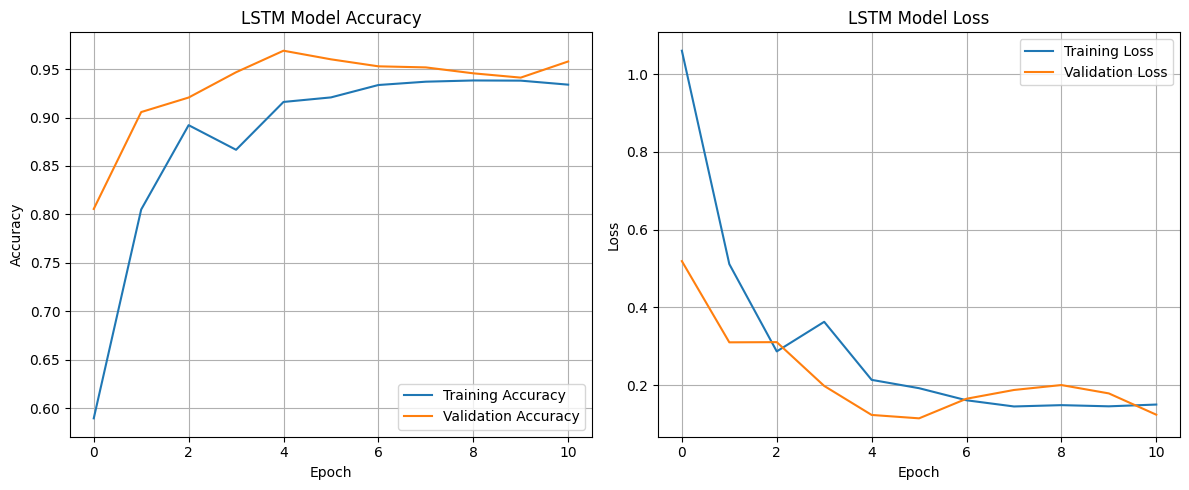

In [47]:

plt.figure(figsize=(12, 5))

# Accuracy graph
plt.subplot(1, 2, 1)

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("LSTM Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)


# Loss graph
plt.subplot(1, 2, 2)

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("LSTM Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [48]:

# Predict test data
y_prob = model.predict(X_test_sensor)

# Get predicted classes
y_pred = np.argmax(y_prob, axis=1)

# Calculate accuracy
test_accuracy = accuracy_score(y_test, y_pred)

print("Final Test Accuracy:",
      round(test_accuracy * 100, 2), "%")

93/93 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step
Final Test Accuracy: 88.02 %


In [42]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [49]:

# Evaluate training data
train_loss, train_acc = model.evaluate(X_tr, y_tr, verbose=0)

# Evaluate validation data
val_loss, val_acc = model.evaluate(X_val, y_val, verbose=0)

# Evaluate testing data
test_loss, test_acc = model.evaluate(X_test_sensor, y_test, verbose=0)

print("TRAINING ACCURACY:", round(train_acc * 100, 2), "%")
print("VALIDATION ACCURACY:", round(val_acc * 100, 2), "%")
print("TESTING ACCURACY:", round(test_acc * 100, 2), "%")

TRAINING ACCURACY: 93.48 %
VALIDATION ACCURACY: 96.0 %
TESTING ACCURACY: 88.02 %


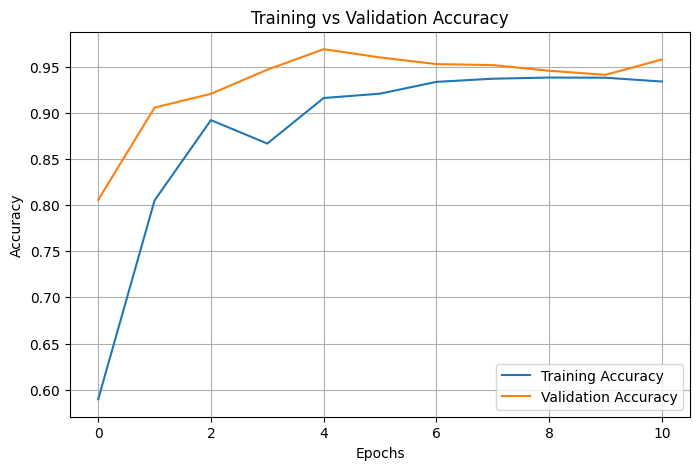

In [53]:
plt.figure(figsize=(8, 5))

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title('Training vs Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.savefig('accuracy.png', dpi=300, bbox_inches='tight')
plt.show()

CLASSIFICATION REPORT

In [50]:
print(classification_report(
    y_test,
    y_pred,
    target_names=[
        "WALKING",
        "WALKING_UPSTAIRS",
        "WALKING_DOWNSTAIRS",
        "SITTING",
        "STANDING",
        "LAYING"
    ]
))

                    precision    recall  f1-score   support

           WALKING       0.98      0.89      0.93       496
  WALKING_UPSTAIRS       0.86      0.94      0.90       471
WALKING_DOWNSTAIRS       0.89      0.98      0.93       420
           SITTING       0.80      0.71      0.75       491
          STANDING       0.77      0.83      0.80       532
            LAYING       1.00      0.95      0.97       537

          accuracy                           0.88      2947
         macro avg       0.88      0.88      0.88      2947
      weighted avg       0.88      0.88      0.88      2947



CONFUSION MATRIX

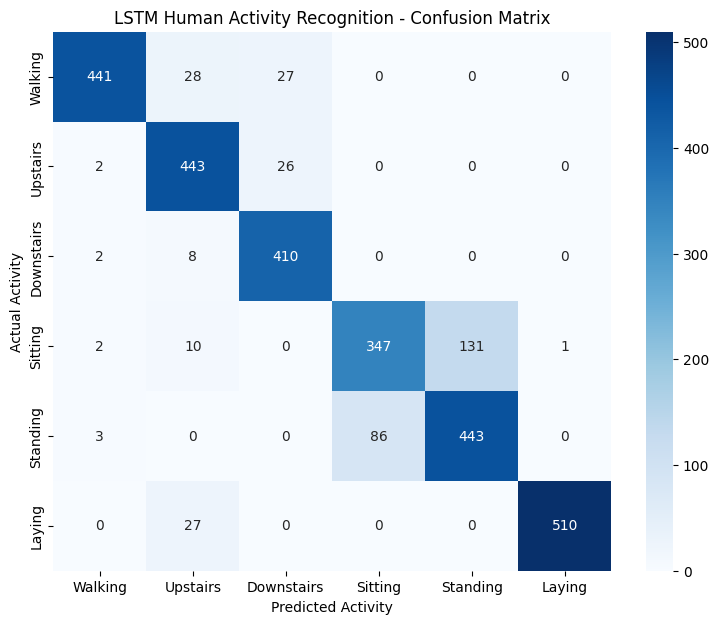

In [51]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[
        "Walking",
        "Upstairs",
        "Downstairs",
        "Sitting",
        "Standing",
        "Laying"
    ],
    yticklabels=[
        "Walking",
        "Upstairs",
        "Downstairs",
        "Sitting",
        "Standing",
        "Laying"
    ]
)

plt.xlabel("Predicted Activity")
plt.ylabel("Actual Activity")
plt.title("LSTM Human Activity Recognition - Confusion Matrix")
plt.show()

In [52]:
model.save("human_activity_lstm.keras")

print("Model saved successfully!")

Model saved successfully!
